# 3. Relaxation and phonons

Phonons, the vibrations of a crystal, follow from the force constants: how the force on each atom
changes when another atom moves. Phonopy obtains them from the forces in a few displaced supercells,
which an MLIP gives in seconds.

Steps: relax the cell and atoms with 7net-0, build displaced supercells with Phonopy, compute their
forces, and plot the phonon band structure and density of states of silicon.

This notebook needs `phonopy` (`pip install phonopy`).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import _tutorial as T

warnings.filterwarnings('ignore', message='.*torch.jit.script.*')   # deprecation inside a dependency, harmless here
plt.rcParams['figure.dpi'] = 200   # sharp inline figures
T.machine_report()

machine : Apple M5 Pro, 52 GB memory, Darwin 27.2.0
python  : 3.13.9, torch 2.15.0, sevenn 0.12.2.dev0
Apple GPU (MPS): yes; fused kernels: available


In [2]:
from ase.build import bulk
from ase.filters import FrechetCellFilter
from ase.optimize import BFGS

label, device, opt = T.best_backend()
calc = T.calculator('7net-0', device, opt)

unit = bulk('Si', 'diamond', a=5.40, cubic=True)      # start a little off the equilibrium lattice
unit.calc = calc
BFGS(FrechetCellFilter(unit), logfile=None).run(fmax=1e-4, steps=200)
a0 = unit.cell.lengths()[0]
print(f'relaxed lattice parameter: {a0:.4f} Å (experiment 5.431 Å; DFT-PBE, the training level of 7net-0, gives about 5.47 Å)')

relaxed lattice parameter: 5.4632 Å (experiment 5.431 Å; DFT-PBE, the training level of 7net-0, gives about 5.47 Å)


## Force constants with Phonopy

A 3 × 3 × 3 supercell of the 8-atom cubic cell (216 atoms). By symmetry, silicon needs a single displaced
supercell.

In [3]:
from phonopy import Phonopy
from phonopy.structure.atoms import PhonopyAtoms

cell = PhonopyAtoms(symbols=unit.get_chemical_symbols(), cell=unit.cell[:], scaled_positions=unit.get_scaled_positions())
phonon = Phonopy(cell, supercell_matrix=np.diag([3, 3, 3]), primitive_matrix='F')   # F: face-centred cubic primitive cell
phonon.generate_displacements(distance=0.01)
scs = phonon.supercells_with_displacements
print(len(scs), 'displaced supercell(s) of', len(scs[0]), 'atoms')

from ase import Atoms


def forces_of(sc, calc):
    a = Atoms(sc.symbols, cell=sc.cell, scaled_positions=sc.scaled_positions, pbc=True)
    a.calc = calc
    return a.get_forces()


t = time.perf_counter()
phonon.forces = [forces_of(sc, calc) for sc in scs]
print(f'forces with {label}: {time.perf_counter() - t:.2f} s')
phonon.produce_force_constants()

1 displaced supercell(s) of 216 atoms
forces with Apple GPU, fused: 0.10 s


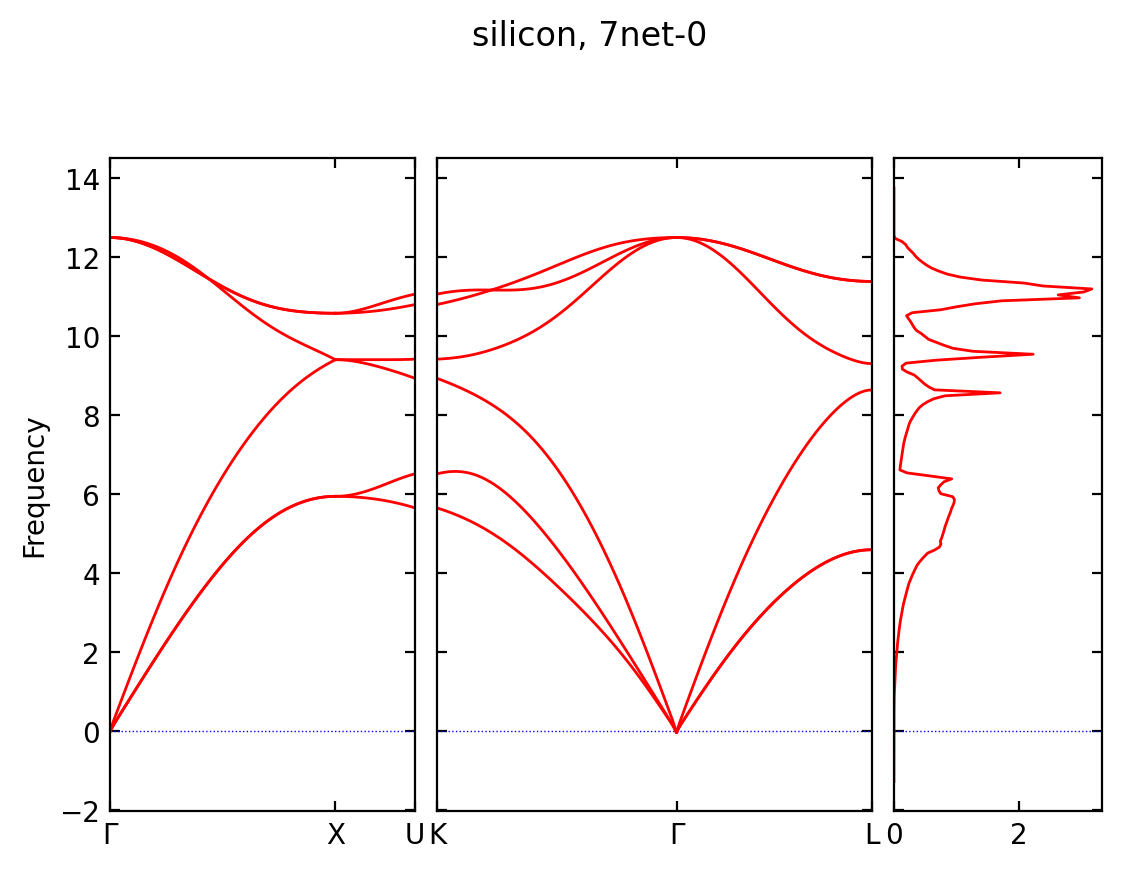

optical frequency at Γ: 12.49 THz (experiment 15.5 THz)


In [4]:
from phonopy.phonon.band_structure import get_band_qpoints_and_path_connections

path = [[[0, 0, 0], [0.5, 0, 0.5], [0.625, 0.25, 0.625]], [[0.375, 0.375, 0.75], [0, 0, 0], [0.5, 0.5, 0.5]]]
labels = ['Γ', 'X', 'U', 'K', 'Γ', 'L']
qpoints, connections = get_band_qpoints_and_path_connections(path, npoints=60)
phonon.run_band_structure(qpoints, path_connections=connections, labels=labels)
phonon.run_mesh([16, 16, 16], is_gamma_center=True)
phonon.run_total_dos()
fig = phonon.plot_band_structure_and_dos()
fig.suptitle('silicon, 7net-0')
plt.show()

freqs = phonon.run_qpoints([[0, 0, 0]]).frequencies[0]
print('optical frequency at Γ: %.2f THz (experiment 15.5 THz)' % max(freqs))

The band structure has the familiar shape of silicon, but the optical branch at Γ is too low: about
12.5 THz, against 15.5 THz measured and about 15 THz from DFT-PBE. This is the model, not the code: every
backend gives the same forces. Universal potentials trained mostly on structures near equilibrium are
known to soften phonons. Larger and more recently trained models do better, which we can check in a
minute, since each phonon calculation takes seconds.

In [5]:
def gamma_optical(model, **kw):
    c = T.calculator(model, device, opt, **kw)
    u = bulk('Si', 'diamond', a=5.40, cubic=True)
    u.calc = c
    BFGS(FrechetCellFilter(u), logfile=None).run(fmax=1e-4, steps=200)
    p = Phonopy(PhonopyAtoms(symbols=u.get_chemical_symbols(), cell=u.cell[:], scaled_positions=u.get_scaled_positions()),
                supercell_matrix=np.diag([3, 3, 3]), primitive_matrix='F')
    p.generate_displacements(distance=0.01)
    p.forces = [forces_of(sc, c) for sc in p.supercells_with_displacements]
    p.produce_force_constants()
    return u.cell.lengths()[0], max(p.run_qpoints([[0, 0, 0]]).frequencies[0])


# 7net-omni is a 100 MB download on first use; set to False to skip it
WITH_OMNI = True
cases = [('7net-0', {}), ('7net-l3i5', {})] + ([('7net-omni', {'modal': 'mpa'}), ('7net-omni', {'modal': 'omat24'})] if WITH_OMNI else [])
for model, kw in cases:
    t = time.perf_counter()
    a_, f_ = gamma_optical(model, **kw)
    print(f'{model:10s} {kw.get("modal", ""):7s} a = {a_:.4f} Å, optical at Γ = {f_:5.2f} THz ({time.perf_counter() - t:.0f} s)')
print('experiment: a = 5.431 Å, 15.5 THz')

7net-0             a = 5.4632 Å, optical at Γ = 12.49 THz (1 s)


7net-l3i5          a = 5.4667 Å, optical at Γ = 12.81 THz (2 s)
Converting model backend...


7net-omni  mpa     a = 5.4702 Å, optical at Γ = 13.72 THz (13 s)
Converting model backend...


7net-omni  omat24  a = 5.4623 Å, optical at Γ = 14.43 THz (13 s)
experiment: a = 5.431 Å, 15.5 THz


The trend is the useful lesson: the choice of model matters more than any setting of the calculation.
For production work on a given material, fine-tuning on a few DFT structures of that material removes
most of the softening.

**Next experiments:** compare the time of the force step on the CPU (`T.calculator('7net-0', 'cpu',
'off')`); a lower-symmetry crystal needs many more displaced supercells, where the speed matters more.